<p style ="text-align:center">
    <img src="http://epecora.com.br/DataFiles/BannerUFPR.png" width="700" alt="PPGOLD/PPGMNE Python:INTRO"  />
</p>


# SAOP09 - Data Science For Business
## Prof. Eduardo Pécora

# Curva ROC e Indicadores
Tempo estimado: **60** minutos

## Objetivos

Após completar esta aula, você será capaz de:

* Interpretar uma Curva ROC
* Calcular e interpretar os indicadores de um modelo de classificação

Accuracy: 0.9649
Precision: 1.0000
Recall: 0.9062
F1 Score: 0.9508
FPR=[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.04672897
 0.04672897 0.05607477 0.06542056 0.08411215 0.10280374 0.11214953
 0.13084112 0.1588785  0.19626168 0.21495327 0.27102804 0.30841121
 0.42990654 0.65420561 1.        ]
 TPR=[0.       0.390625 0.515625 0.625    0.65625  0.75     0.796875 0.8125
 0.84375  0.921875 0.953125 0.953125 0.96875  0.96875  0.984375 0.984375
 0.984375 1.       1.       1.       1.       1.       1.       1.
 1.       1.       1.      ]
 Thresholds=[ inf 1.   0.99 0.98 0.97 0.79 0.78 0.74 0.72 0.49 0.42 0.26 0.25 0.23
 0.2  0.16 0.15 0.14 0.13 0.09 0.08 0.06 0.04 0.03 0.02 0.01 0.  ]


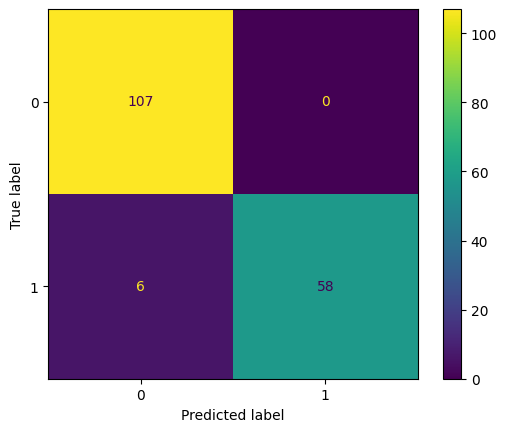

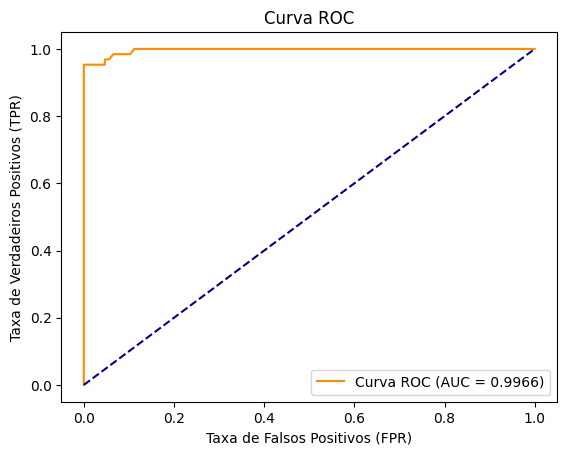

In [2]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

# Load the breast cancer dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(1- data.target, name="Maligno")

# Split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Treinando o modelo
clf = RandomForestClassifier(random_state=0)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:, 1]

# Matriz de confusão e métricas
conf_matrix = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=clf.classes_).plot()

# Calculando métricas
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

# Curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
print(f'FPR={fpr}\n TPR={tpr}\n Thresholds={thresholds}')

# Plotando a curva ROC
plt.figure()
plt.plot(fpr, tpr, color='darkorange', label=f'Curva ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Curva ROC')
plt.legend(loc="lower right")
plt.show()

## Fique Conectado

- [![YouTube](https://img.icons8.com/?size=40&id=19318&format=png&color=000000)](https://www.youtube.com/@LigaDataScience/videos)  
  Explore nossos vídeos educacionais e webinars sobre ciência de dados, machine learning e inteligência artificial. Inscreva-se para não perder nenhuma atualização!

- [![LinkedIn](https://img.icons8.com/?size=40&id=13930&format=png&color=000000)](https://www.linkedin.com/company/liga-data-science-ufpr/)  
  Siga-nos no LinkedIn para as últimas novidades, oportunidades de carreira e networking profissional no campo da ciência de dados.

- [![Instagram](https://img.icons8.com/?size=40&id=32323&format=png&color=000000)](https://www.instagram.com/ligadatascience/)  
  Confira nosso Instagram para conteúdos dos bastidores, destaques de eventos e o dia a dia da Liga Data Science. Faça parte da nossa jornada!
  

## Autores

<a href="https://www.linkedin.com/in/eduardopecora/" target="_blank">Eduardo Pecora</a>

<a href="https://www.linkedin.com/in/joão-gabriel-santin-botelho/" target="_blank">João Gabriel</a>

## Referências:

* Documentação da biblioteca <a href="https://scikit-learn.org/stable/">SciKit Learn</a>

## Log de modificações

| Data | Versão | Modificado por | Descrição |
| ----------------- | ------- | ---------- | ---------------------------------- |
| 28-05-2024       | 1.0     | Eduardo Pecora    | Inicial               |
| 05-11-2024       | 1.1     | João Gabriel    | Aula               |

<hr>

&copy; Liga Data Science 2024